# LinkedIn Connections Segmentation

Segments my LinkedIn connections by **company**, **company category**, **role/function**, **seniority**, and **title**,
using `export2/Connections.csv` from the LinkedIn data export (identical to the copy in `export1.zip/`).

> **Location is not included.** LinkedIn's `Connections.csv` only contains name, profile URL, email (rarely),
> company, position and connection date — there is no location field. A **connection-year timeline** is used
> as the extra dimension instead.

Segments are rule-based (keyword matching on company names and job titles). The rule tables in sections 2–4
can be edited and the notebook re-run.

## 1. Load & clean

## 2. Companies

Company names are normalized first so variants roll up (e.g. *Amazon Web Services (AWS)* → *Amazon*).

Unique companies after normalization: 991


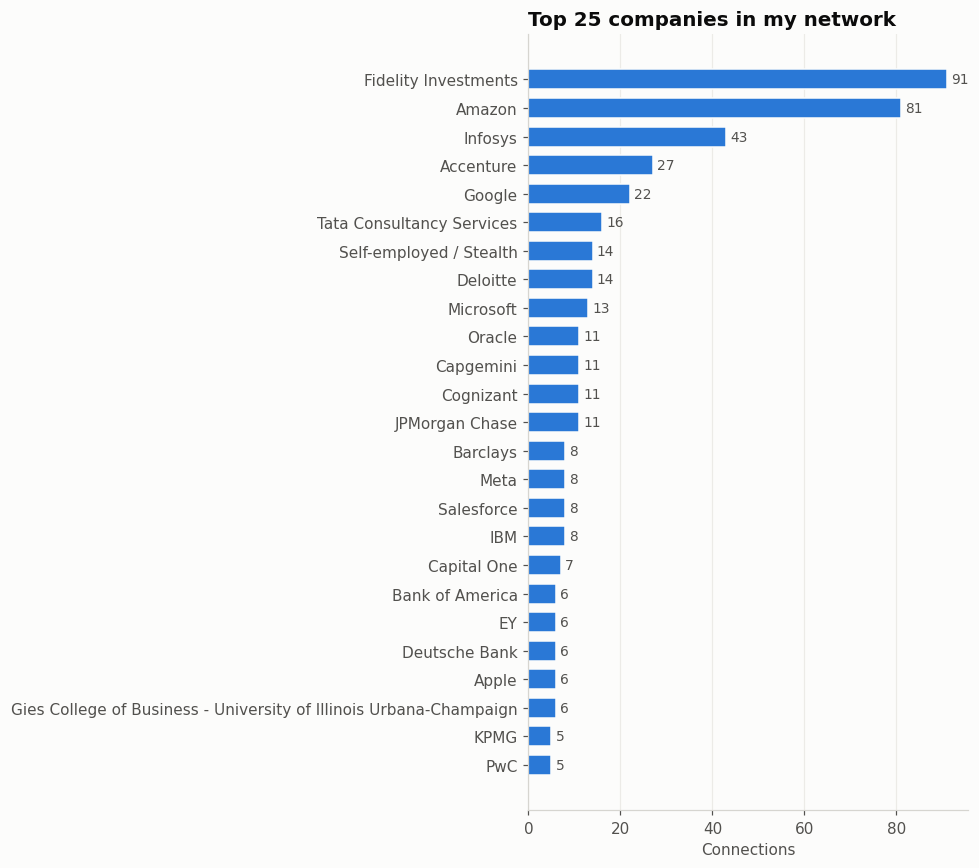

In [3]:
COMPANY_ALIASES = {
    r"^amazon|^aws\b|amazon web services": "Amazon",
    r"^google|^alphabet|^youtube|^deepmind": "Google",
    r"^microsoft|^linkedin$|^github$": "Microsoft",
    r"^meta\b|^facebook|^instagram|^whatsapp": "Meta",
    r"^fidelity|^fmr\b|^fidelity international": "Fidelity Investments",
    r"tata consultancy|^tcs\b": "Tata Consultancy Services",
    r"^infosys": "Infosys",
    r"^accenture": "Accenture",
    r"^deloitte": "Deloitte",
    r"^cognizant": "Cognizant",
    r"^capgemini": "Capgemini",
    r"^ibm\b": "IBM",
    r"^oracle": "Oracle",
    r"^jp ?morgan|^jpmorgan|^j\.p\. morgan|^chase\b": "JPMorgan Chase",
    r"^wipro": "Wipro",
    r"^hcl": "HCLTech",
    r"^ey\b|^ernst & young": "EY",
    r"^pwc|pricewaterhouse": "PwC",
    r"^kpmg": "KPMG",
    r"^salesforce": "Salesforce",
    r"^udacity": "Udacity",
    r"self[- ]employed|^freelance|^independent|^stealth": "Self-employed / Stealth",
}

def normalize_company(name):
    if not name:
        return "Unknown"
    low = name.lower()
    for pattern, canonical in COMPANY_ALIASES.items():
        if re.search(pattern, low):
            return canonical
    return name

df["Company (normalized)"] = df["Company"].map(normalize_company)
print(f"Unique companies after normalization: {df['Company (normalized)'].nunique():,}")
top_companies = df.loc[df["Company (normalized)"] != "Unknown", "Company (normalized)"].value_counts().head(25)
hbar(top_companies, "Top 25 companies in my network", figsize=(9, 8))

### Company category

Each company is mapped to a broad industry bucket by keyword. Anything unmatched falls into **Other / Startups**.

,Connections,Share %
Company Category,,
Other / Startups,750,47.3
IT Services & Consulting,246,15.5
Financial Services,206,13.0
Big Tech,203,12.8
Education & EdTech,65,4.1
Unknown,54,3.4
Healthcare & Pharma,32,2.0
"Retail, Consumer & Media",17,1.1
Self-employed / Stealth,14,0.9


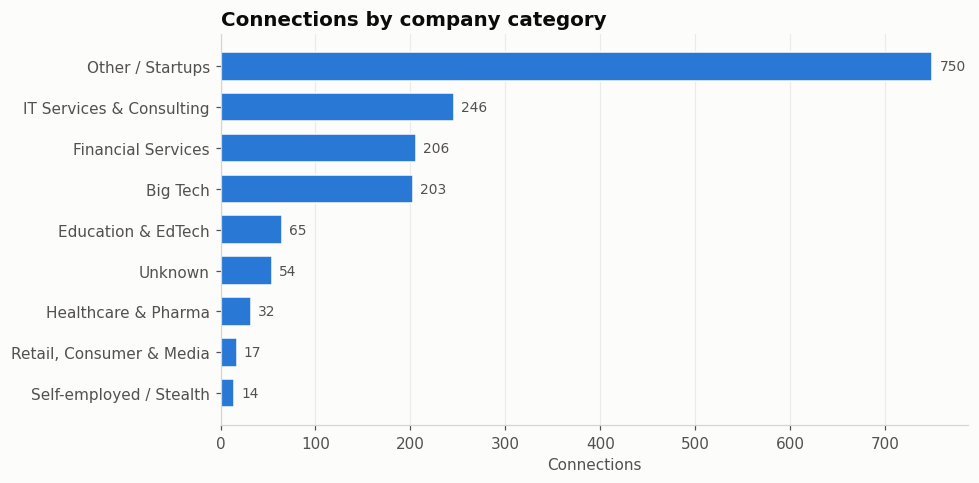

In [4]:
COMPANY_CATEGORIES = [
    ("Big Tech", r"^(amazon|google|microsoft|meta|apple|netflix|oracle|salesforce|ibm|adobe|intel|nvidia|cisco|sap|uber|airbnb|linkedin|twitter|x corp|vmware|dell|hp\b|hewlett|qualcomm|paypal|ebay|workday|servicenow|snowflake|databricks|atlassian|intuit|walmart global tech|spotify|tiktok|bytedance|openai|anthropic)"),
    ("IT Services & Consulting", r"(infosys|tata consultancy|accenture|cognizant|capgemini|deloitte|wipro|hcltech|tech mahindra|mindtree|ltimindtree|l&t|mphasis|virtusa|ey\b|pwc|kpmg|mckinsey|boston consulting|bain|zs associates|genpact|ntt data|dxc|epam|globallogic|hexaware|syntel|igate|birlasoft|persistent|zensar|cgi\b|slalom|thoughtworks|consult|solutions|technologies|infotech|systems|software)"),
    ("Financial Services", r"(fidelity|barclays|capital one|jpmorgan|goldman|morgan stanley|wells fargo|bank|citi|hsbc|american express|amex|visa\b|mastercard|blackrock|vanguard|schwab|state street|ubs|credit suisse|deutsche|bny|northern trust|td |truist|insurance|financial|capital|invest|securities|asset management|wealth|fintech|paytm|razorpay|stripe)"),
    ("Education & EdTech", r"(udacity|university|college|school|institute|academy|iit\b|iim\b|coursera|edx|byju|upgrad|great learning|simplilearn|interview kickstart|education|learning)"),
    ("Healthcare & Pharma", r"(health|hospital|pharma|medical|clinic|biotech|labs\b|cvs|unitedhealth|optum|pfizer|novartis|johnson & johnson|cerner|epic systems)"),
    ("Retail, Consumer & Media", r"(retail|target|costco|kroger|nike|starbucks|unilever|procter|p&g|pepsi|coca|nestle|flipkart|myntra|swiggy|zomato|media|news|disney|warner|entertainment)"),
    ("Self-employed / Stealth", r"^self-employed / stealth$"),
]

def company_category(name):
    if name == "Unknown":
        return "Unknown"
    low = name.lower()
    for cat, pattern in COMPANY_CATEGORIES:
        if re.search(pattern, low):
            return cat
    return "Other / Startups"

df["Company Category"] = df["Company (normalized)"].map(company_category)
cat_counts = df["Company Category"].value_counts()
display(pd.DataFrame({"Connections": cat_counts, "Share %": (cat_counts / len(df) * 100).round(1)}))
hbar(cat_counts, "Connections by company category", color=PALETTE[0], figsize=(9, 4.5))

## 3. Seniority (from job title)

Rules are checked **top to bottom**; the first match wins, so more senior levels are listed first.

,Connections,Share %
Seniority,,
Student / Intern,12,0.8
C-Suite / Founder,121,7.6
VP / Head,149,9.4
Director,138,8.7
Manager,358,22.6
Lead / Principal / Staff,195,12.3
Senior IC,178,11.2
Individual Contributor,385,24.3
Unknown,51,3.2


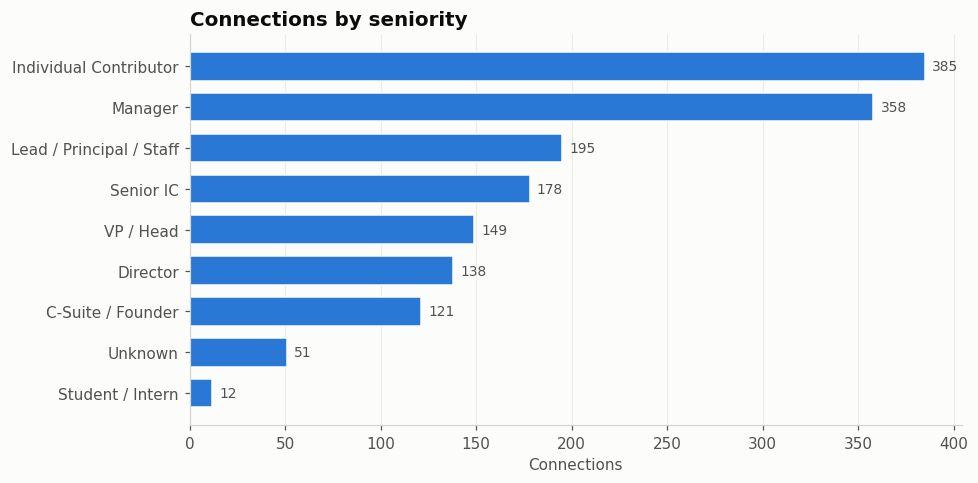

In [5]:
SENIORITY_RULES = [
    ("Student / Intern",        r"\b(student|intern|internship|trainee|graduate assistant|research assistant|fresher|aspiring)\b"),
    ("C-Suite / Founder",       r"\b(ceo|cto|cfo|coo|cio|cdo|cpo|cmo|chief|founder|co-founder|cofounder|(?<!product )owner|(?<!vice )president|(?<!client )(?<!business )partner|managing director|board member)\b"),
    ("VP / Head",               r"\b(vp|svp|evp|avp|vice president|head of|head,|head\b|general manager|gm\b)"),
    ("Director",                r"\b(director)\b"),
    ("Manager",                 r"\b(manager|mgr|management)\b"),
    ("Lead / Principal / Staff", r"\b(lead|principal|staff|architect|distinguished|fellow|expert|specialist lead|team lead|tech lead)\b"),
    ("Senior IC",               r"\b(senior|sr\.?|sr\b|ii+|iii|level 3|l5|l6)\b"),
    ("Individual Contributor",  r"."),   # any other non-empty title
]

def seniority(title):
    if not title:
        return "Unknown"
    low = title.lower()
    for level, pattern in SENIORITY_RULES:
        if re.search(pattern, low):
            return level
    return "Unknown"

SENIORITY_ORDER = [lvl for lvl, _ in SENIORITY_RULES] + ["Unknown"]
df["Seniority"] = pd.Categorical(df["Position"].map(seniority), categories=SENIORITY_ORDER, ordered=True)
sen_counts = df["Seniority"].value_counts().reindex(SENIORITY_ORDER)
display(pd.DataFrame({"Connections": sen_counts, "Share %": (sen_counts / len(df) * 100).round(1)}))
hbar(sen_counts,"Connections by seniority", color=PALETTE[0], figsize=(9, 4.5))

## 4. Role / function (from job title)

Again first match wins — specific functions (e.g. *Product*, *Data*) come before generic ones (*Engineering*, *Consulting*).

,Connections,Share %
Function,,
Engineering & IT,306,19.3
Management (general),220,13.9
"Data, Analytics & AI/ML",212,13.4
Consulting & Business Analysis,115,7.2
"Sales, Marketing & BD",114,7.2
Founder / Executive,109,6.9
Program & Project Mgmt,86,5.4
Product Management,72,4.5
Other,67,4.2


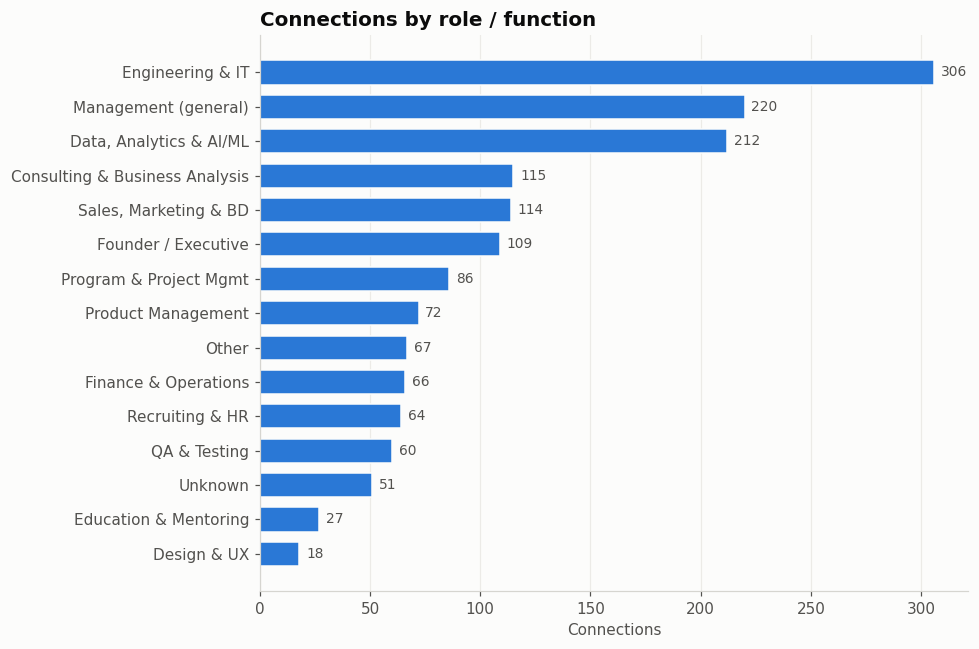

In [6]:
FUNCTION_RULES = [
    ("Recruiting & HR",           r"(recruit|talent|human resources|\bhr\b|hrbp|people partner|people operations|staffing|sourcer)"),
    ("Product Management",        r"(product manag|product owner|product lead|\bpm\b|product director|director.*product|head of product|vp.*product|product strategy|chief product|group product|product management)"),
    ("Data, Analytics & AI/ML",   r"(data(?!base)|analytic|machine learning|\bml\b|\bai\b|artificial intelligence|scientist|statistic|business intelligence|\bbi\b|insight|quantitative|decision science|deep learning|nlp|computer vision|tableau|power bi)"),
    ("Design & UX",               r"(design|ux|ui\b|user experience|user research|creative)"),
    ("QA & Testing",              r"(test|qa\b|quality assurance|quality engineer|sdet|automation engineer)"),
    ("Program & Project Mgmt",    r"(program manag|project manag|programme|delivery manag|scrum|agile coach|pmo|technical program|\btpm\b|release manag|project lead|project coordinator)"),
    ("Sales, Marketing & BD",     r"(sales|marketing|business development|account (manager|executive|director)|growth|brand|customer success|partnership|go-to-market|gtm|pre-sales|presales|client partner|communications|content|seo|social media|evangelist)"),
    ("Finance & Operations",      r"(financ|accountant|accounting|audit|tax|operations|ops\b|treasury|risk|compliance|controller|procurement|supply chain|logistics|underwrit|actuar)"),
    ("Education & Mentoring",     r"(teacher|professor|lecturer|faculty|instructor|mentor|coach|tutor|educator|trainer|teaching)"),
    ("Founder / Executive",       r"(founder|ceo|chief|(?<!vice )president|owner|managing director|partner\b|general manager|board)"),
    ("Engineering & IT",          r"(engineer|developer|software|programmer|architect|devops|sre\b|reliability|cloud|infrastructure|technical|technology|\bit\b|systems|security|network|database|dba|full stack|frontend|front end|backend|back end|mainframe|sap |salesforce|tech lead|coder|sde\b|administrator)"),
    ("Consulting & Business Analysis", r"(consult|business analyst|analyst|advisor|strategy|strategist|specialist)"),
    ("Management (general)",      r"(manager|director|vice president|\b[as]?vp\b|head|lead|associate|executive)"),
]

def function(title):
    if not title:
        return "Unknown"
    low = title.lower()
    for fn, pattern in FUNCTION_RULES:
        if re.search(pattern, low):
            return fn
    return "Other"

df["Function"] = df["Position"].map(function)
fn_counts = df["Function"].value_counts()
display(pd.DataFrame({"Connections": fn_counts, "Share %": (fn_counts / len(df) * 100).round(1)}))
hbar(fn_counts, "Connections by role / function", color=PALETTE[0], figsize=(9, 6))

In [7]:
# Sample of titles that did not match any function rule — useful for refining FUNCTION_RULES
df.loc[df["Function"] == "Other", "Position"].value_counts().head(25)

Position
Proprietor                                       2
Principal                                        2
Student                                          2
Development Expert                               1
Knitwear Intern                                  1
Outreach Volunteer                               1
Homemaker                                        1
Business Process Modeller                        1
Certified Brennan Integration Practitioner       1
Trainee                                          1
RT                                               1
Clerk                                            1
Application Development                          1
Maths                                            1
Graduate Student                                 1
项目工程师                                            1
Works at                                         1
Senior Pharmacy Account Representative | West    1
Summer Intern                                    1
The Big Health Industr

## 5. Cross-segments

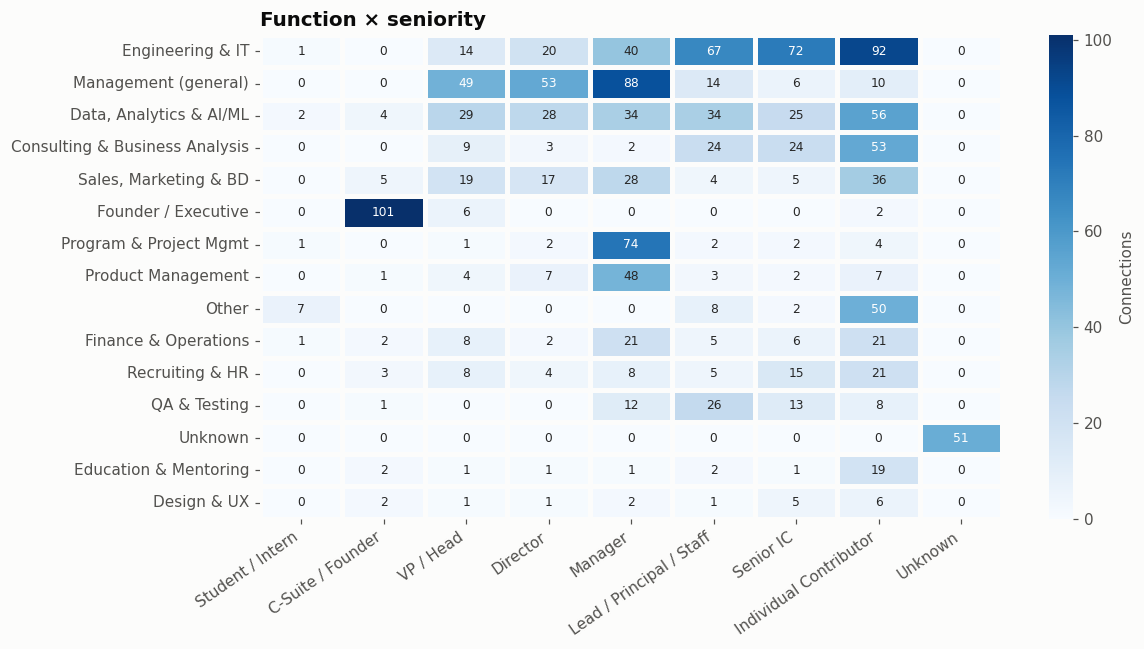

In [8]:
def heatmap(table, title, figsize=(11, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(table, annot=True, fmt="d", cmap="Blues", linewidths=2, linecolor="#fcfcfb",
                cbar_kws={"label": "Connections"}, ax=ax, annot_kws={"fontsize": 8})
    ax.set_title(title, loc="left")
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.grid(False)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

fn_order = fn_counts.index.tolist()
heatmap(pd.crosstab(df["Function"], df["Seniority"]).reindex(fn_order),
        "Function × seniority")

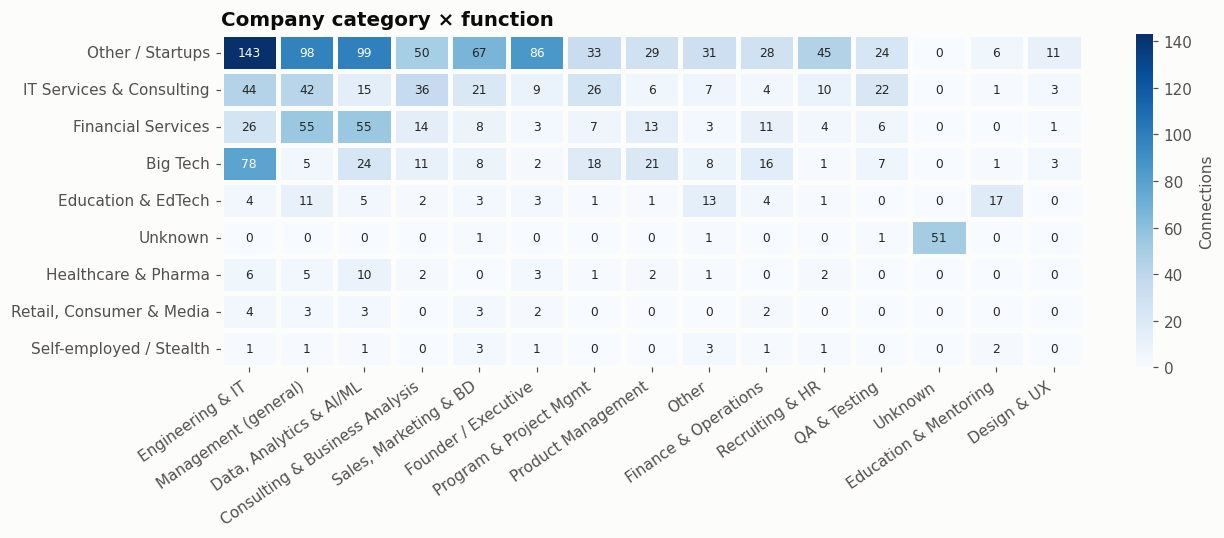

In [9]:
heatmap(pd.crosstab(df["Company Category"], df["Function"]).reindex(columns=fn_order).loc[cat_counts.index],
        "Company category × function", figsize=(12, 5))

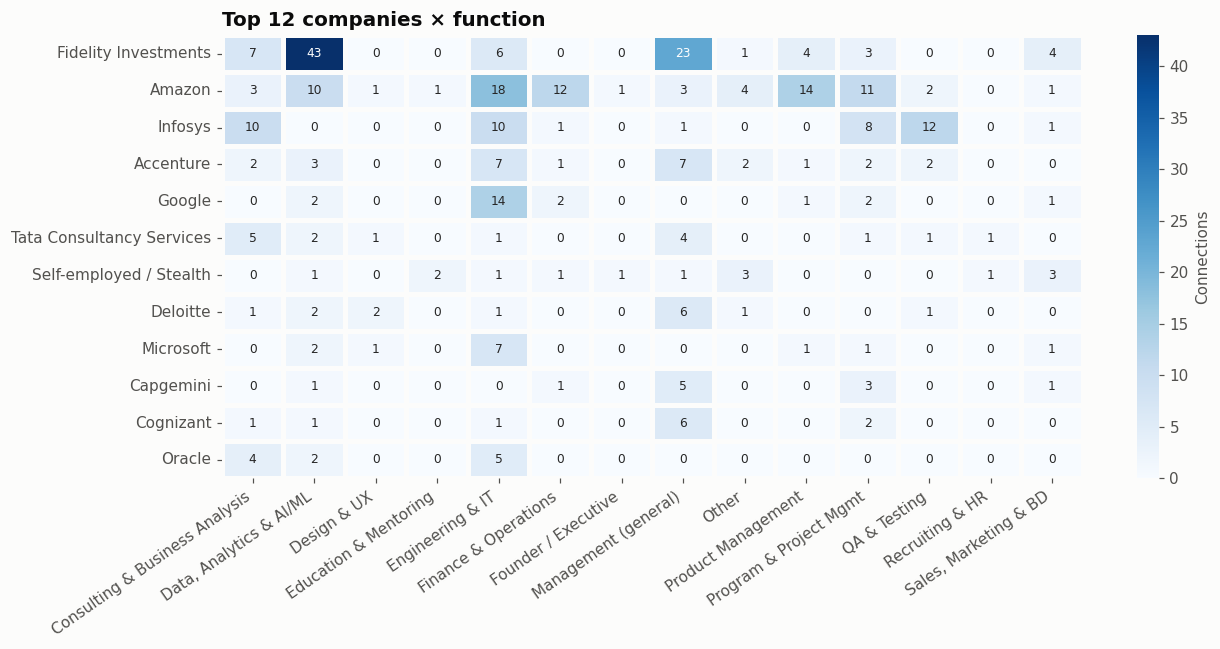

In [10]:
top12 = top_companies.head(12).index
sub = df[df["Company (normalized)"].isin(top12)]
heatmap(pd.crosstab(sub["Company (normalized)"], sub["Function"]).loc[top12],
        "Top 12 companies × function", figsize=(12, 6))

## 6. Timeline — when I connected (in place of location)

Since location isn't in the export, the year of connection shows how the network was built over time.

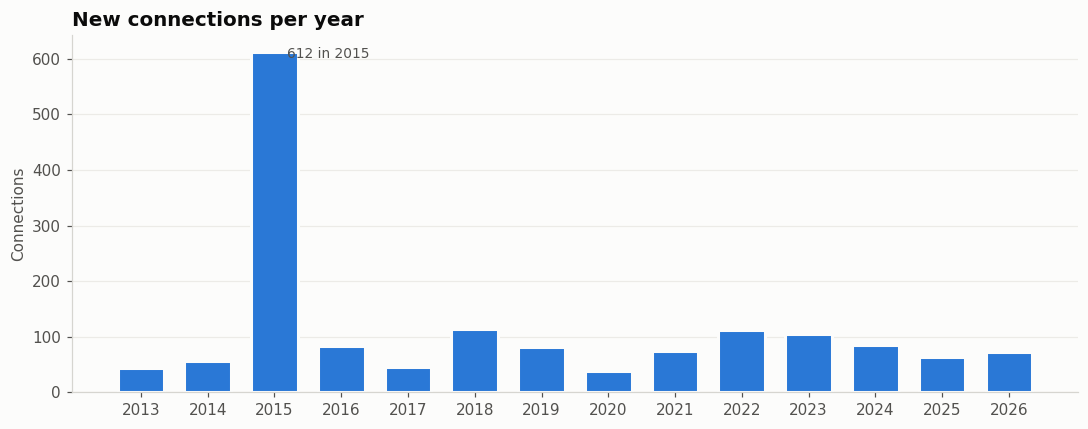

In [11]:
year_counts = df["Year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(year_counts.index.astype(int).astype(str), year_counts.values, color=PALETTE[0],
       width=0.7, edgecolor="#fcfcfb", linewidth=2)
ax.grid(axis="x", visible=False)
peak = year_counts.idxmax()
ax.annotate(f"{year_counts.max():,} in {int(peak)}", xy=(str(int(peak)), year_counts.max()),
            xytext=(8, -4), textcoords="offset points", color=INK_2, fontsize=9)
ax.set_title("New connections per year", loc="left")
ax.set_ylabel("Connections")
plt.tight_layout(); plt.show()

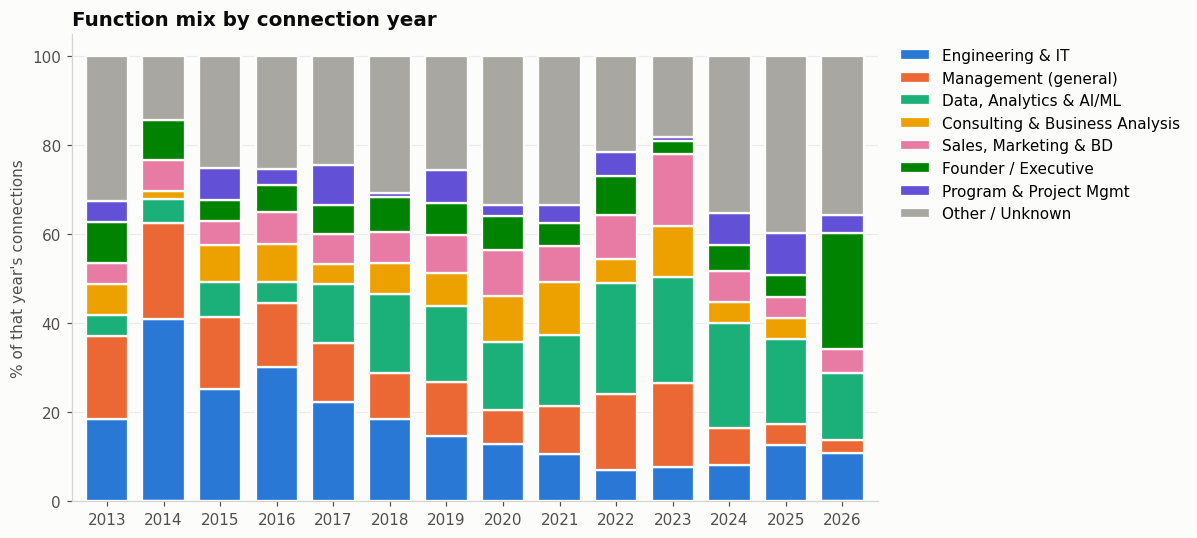

In [12]:
def stacked_share_by_year(col, title, top_n=7):
    """100% stacked bars by year; keeps the top_n categories and folds the rest into 'Other'."""
    keep = df[col].value_counts().drop(["Unknown", "Other"], errors="ignore").head(top_n).index
    s = df[col].astype(str).where(df[col].astype(str).isin(keep), "Other / Unknown")
    t = pd.crosstab(df["Year"].astype(int), s, normalize="index") * 100
    t = t[list(keep) + (["Other / Unknown"] if "Other / Unknown" in t else [])]
    colors = PALETTE[:len(keep)] + [OTHER_GREY]
    ax = t.plot(kind="bar", stacked=True, figsize=(11, 5), color=colors, width=0.75,
                edgecolor="#fcfcfb", linewidth=1.5)
    ax.set_title(title, loc="left"); ax.set_ylabel("% of that year's connections"); ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()

stacked_share_by_year("Function", "Function mix by connection year")

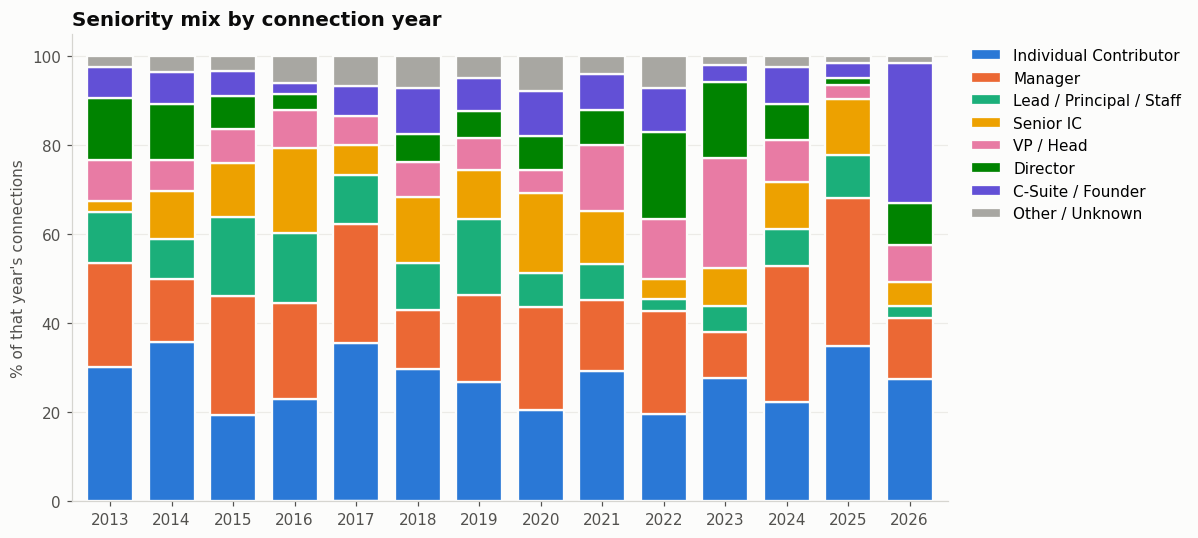

In [13]:
stacked_share_by_year("Seniority", "Seniority mix by connection year")

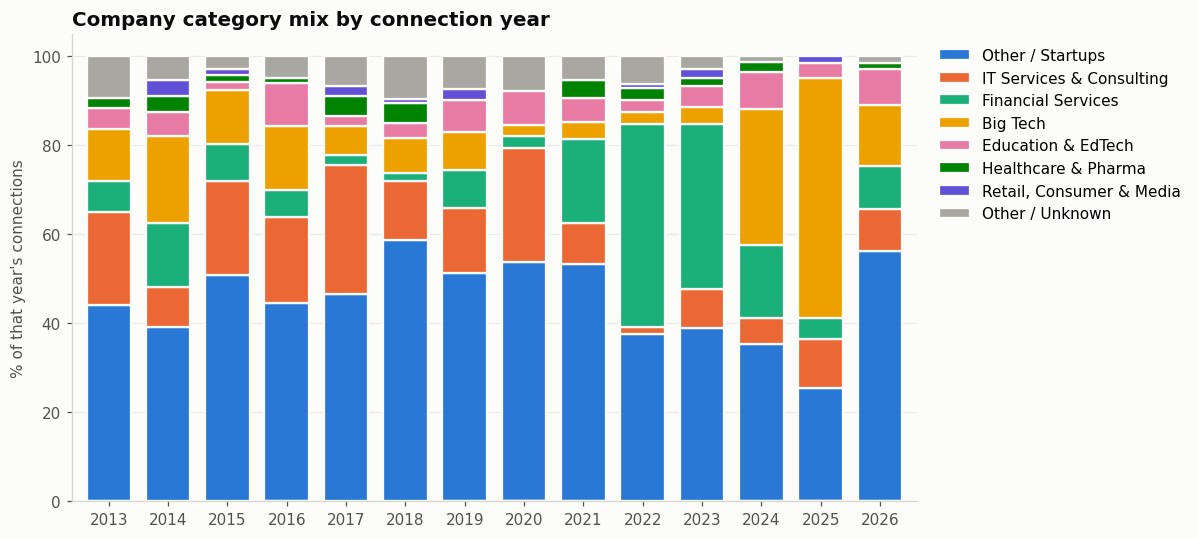

In [14]:
stacked_share_by_year("Company Category", "Company category mix by connection year")

## 7. Title keywords

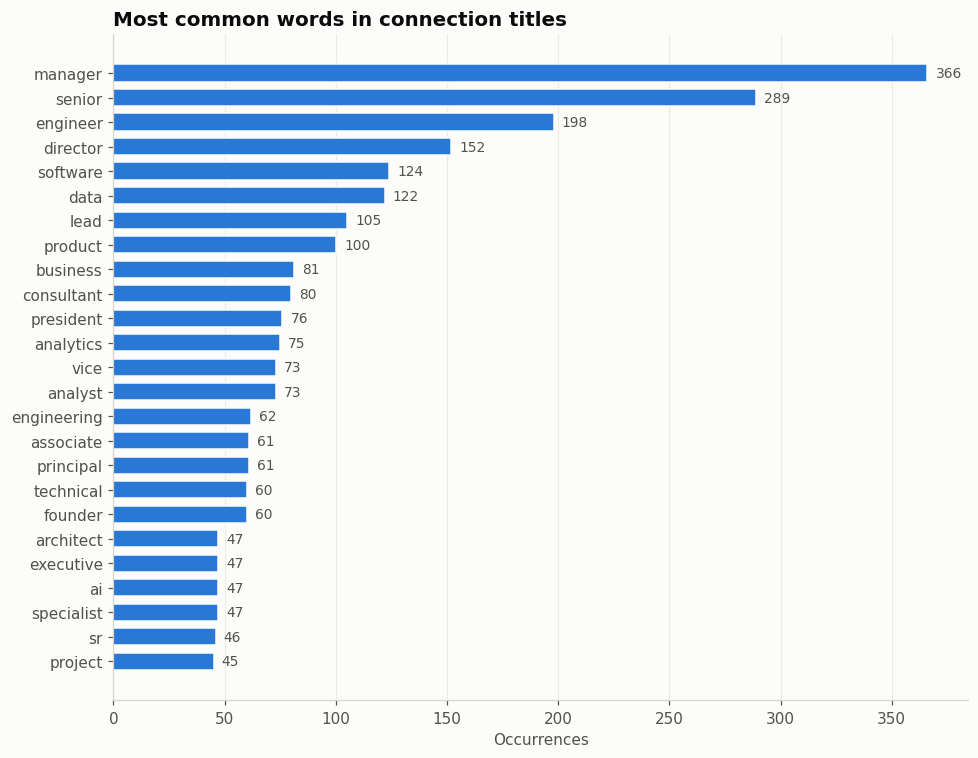

In [15]:
STOP = {"of", "and", "the", "&", "-", "|", "at", "in", "for", "a", "to", "–", "/", "on", "@", ","}
words = (df["Position"].str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split().explode())
words = words[~words.isin(STOP) & words.notna() & (words.str.len() > 1)]
hbar(words.value_counts().head(25), "Most common words in connection titles", xlabel="Occurrences", figsize=(9, 7))

## 8. How diverse is the network?

"Diverse" here means **professional diversity**: how evenly connections are spread across companies, industries,
functions and seniority levels. The export has no location field. Gender and ethnicity aren't in it either,
and guessing them from names would be unreliable and unfair, so those dimensions are **not assessed**.

Three measures, each on a different scale:

| Measure | What it answers | How to read it |
|---|---|---|
| **Evenness** (normalized Shannon entropy) | Are connections spread evenly across the groups that exist? | 0 = everyone in one group, 1 = perfectly even. Above ~0.8 is well spread. |
| **HHI** (Herfindahl–Hirschman index, sum of squared shares) | How concentrated is it? Same idea economists use for market concentration. | Below 0.15 = unconcentrated, 0.15–0.25 = moderate, above 0.25 = concentrated. |
| **Top-1 / Top-10 share** | How much does the biggest group (or 10 biggest) dominate? | The easiest to read: the share of connections in the largest groups. |

Evenness and HHI can disagree when the number of groups differs. Company has ~1,000 groups, seniority has 9.
That's why all three are shown together.

In [16]:
import numpy as np

def evenness(s):
    p = s.value_counts(normalize=True)
    return float(-(p * np.log(p)).sum() / np.log(len(p))) if len(p) > 1 else 0.0

def diversity_row(col):
    s = df[col].astype(str)
    p = s.value_counts(normalize=True)
    return {"Groups": len(p), "Evenness (0–1)": round(evenness(s), 2), "HHI": round(float((p ** 2).sum()), 3),
            "Top-1 share %": round(p.iloc[0] * 100, 1), "Top-1 group": p.index[0],
            "Top-10 share %": round(p.head(10).sum() * 100, 1)}

diversity = pd.DataFrame({c: diversity_row(c) for c in
                          ["Company (normalized)", "Company Category", "Function", "Seniority"]}).T
display(diversity)

company_counts = df.loc[df["Company (normalized)"] != "Unknown", "Company (normalized)"].value_counts()
solo = (company_counts == 1).sum()
print(f"Companies where I know exactly one person: {solo:,} ({solo / company_counts.sum() * 100:.0f}% of connections)")

named = df[~df["Company Category"].isin(["Other / Startups", "Unknown"])]
print("\nIndustry mix among connections with a recognised category:")
print((named["Company Category"].value_counts(normalize=True) * 100).round(1).to_string())

,Groups,Evenness (0–1),HHI,Top-1 share %,Top-1 group,Top-10 share %
Company (normalized),991,0.89,0.01,5.7,Fidelity Investments,23.6
Company Category,9,0.72,0.284,47.3,Other / Startups,100.0
Function,15,0.91,0.102,19.3,Engineering & IT,86.1
Seniority,9,0.89,0.161,24.3,Individual Contributor,100.0


Companies where I know exactly one person: 880 (57% of connections)

Industry mix among connections with a recognised category:
Company Category
IT Services & Consulting    31.4
Financial Services          26.3
Big Tech                    25.9
Education & EdTech           8.3
Healthcare & Pharma          4.1
Retail, Consumer & Media     2.2
Self-employed / Stealth      1.8


### Reading the diversity results (Oct 2026 export)

- **Companies: very diverse.** About 990 companies, evenness ~0.89 and HHI ~0.01 (far below the 0.15
  "unconcentrated" line). The 10 biggest employers hold only ~24% of connections, and more than half of
  connections are the only person I know at their company. No single employer dominates.
- **Functions: diverse.** 15 function groups with evenness ~0.91. The largest, Engineering & IT, is under 20%.
- **Seniority: balanced.** Every level from individual contributor to C-suite has a meaningful share. About a quarter
  are Director level or above.
- **Industry: narrow.** This is the weak spot. *Company Category* has the highest HHI (~0.28, "concentrated").
  Among connections whose industry could be identified, **tech, IT services and finance make up most of the
  network**, while healthcare, retail/media, government, nonprofit and manufacturing barely appear.
  (The big *Other / Startups* bucket is mostly small tech and analytics companies the keyword rules don't
  recognise, so it doesn't change this picture.)

**Verdict:** the network is diverse in *who* (companies, roles, levels) but not in *where* (industries). It's
broad within the tech, finance and analytics world rather than across the wider economy.

## 9. My network vs. my career timeline

Here I line up **when connections were made** against **my own job history** (`Positions.csv`).
Each connection is assigned to the era I was in on the day we connected. Then, for each era, I look at:

- **Pace**: connections per month, comparable across eras of different lengths
- **Who**: top companies, function mix, seniority mix, and share at Director level or above
- **Source**: how many connections came from my employer at the time

The eras are taken from `Positions.csv`. Overlapping freelance consulting roles are merged into one era.
The 2011–2017 stretch has no position listed after Infosys, so it gets its own era.

In [17]:
positions = pd.read_csv(DATA.parent / "Positions.csv")
display(positions[["Company Name", "Title", "Location", "Started On", "Finished On"]].fillna(""))

ERAS = [  # (label, start, end): built from Positions.csv; edit if the profile changes
    ("1 · Post-Infosys (no role listed)",          "2013-01-01", "2017-11-30"),
    ("2 · Freelance DS consulting",                "2017-12-01", "2021-10-31"),
    ("3 · Fidelity (Sr Mgr → Director)",           "2021-11-01", "2024-08-31"),
    ("4 · Amazon (Analytics Mgr)",                 "2024-09-01", "2025-12-31"),
    ("5 · Udacity faculty & mentoring",            "2026-01-01", str(df["Connected On"].max().date())),
]
ERA_EMPLOYER = {ERAS[2][0]: "Fidelity Investments", ERAS[3][0]: "Amazon"}

def era_of(date):
    for label, start, end in ERAS:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return label
    return "Unassigned"

df["Career Era"] = df["Connected On"].map(era_of)
SENIOR = ["C-Suite / Founder", "VP / Head", "Director"]

rows = []
for label, start, end in ERAS:
    s = df[df["Career Era"] == label]
    months = (pd.Timestamp(end) - pd.Timestamp(start)).days / 30.44
    fn = s["Function"].value_counts(normalize=True)
    employer = ERA_EMPLOYER.get(label)
    rows.append({
        "Era": label, "Connections": len(s), "Per month": round(len(s) / months, 1),
        "Director+ %": round(s["Seniority"].isin(SENIOR).mean() * 100),
        "Data/AI %": round(fn.get("Data, Analytics & AI/ML", 0) * 100),
        "Founder/Exec %": round(fn.get("Founder / Executive", 0) * 100),
        "From then-employer": (s["Company (normalized)"] == employer).sum() if employer else "—",
        "Top companies": ", ".join(s.loc[s["Company (normalized)"] != "Unknown", "Company (normalized)"]
                                    .value_counts().head(4).index),
    })
eras_table = pd.DataFrame(rows).set_index("Era")
eras_table

,Company Name,Title,Location,Started On,Finished On
0,Udacity,Mentor,,Jan 2026,
1,Udacity Institute of AI & Technology,Faculty Member,,May 2026,
2,Executive Women's Forum (EWF) | DSG Global,Mentor,,May 2026,
3,Amazon,"Analytics Manager, Trust & Safety","Bellevue, WA",Sep 2024,Dec 2025
4,Fidelity Investments,"Director, Advanced Analytics and Insights","North Carolina, United States",Sep 2023,Aug 2024
5,Fidelity Investments,"Senior Manager, Analytics and Insights",,Nov 2021,Aug 2023
6,Springboard,Data Science Consultant,,Jan 2021,Oct 2021
7,Udacity,Data Science Consultant,Greater Chicago Area,Dec 2019,Oct 2021
8,Coursera,Data Science Consultant,,Dec 2019,Oct 2021
9,NCSA Next College Student Athlete,Data Science Consultant,"Chicago, Illinois",Sep 2018,Dec 2019


,Connections,Per month,Director+ %,Data/AI %,Founder/Exec %,From then-employer,Top companies
Era,,,,,,,
1 · Post-Infosys (no role listed),830,14.1,20,7,6,—,"Infosys, Accenture, Amazon, Google"
2 · Freelance DS consulting,305,6.5,24,16,7,—,"Self-employed / Stealth, Tata Consultancy Serv..."
3 · Fidelity (Sr Mgr → Director),280,8.2,43,25,6,87,"Fidelity Investments, Amazon, Gies College of ..."
4 · Amazon (Analytics Mgr),99,6.2,9,18,4,50,"Amazon, Gies College of Business - University ..."
5 · Udacity faculty & mentoring,73,7.7,49,15,26,—,"Amazon, JPMorgan Chase, Microsoft, TEDxSammami..."


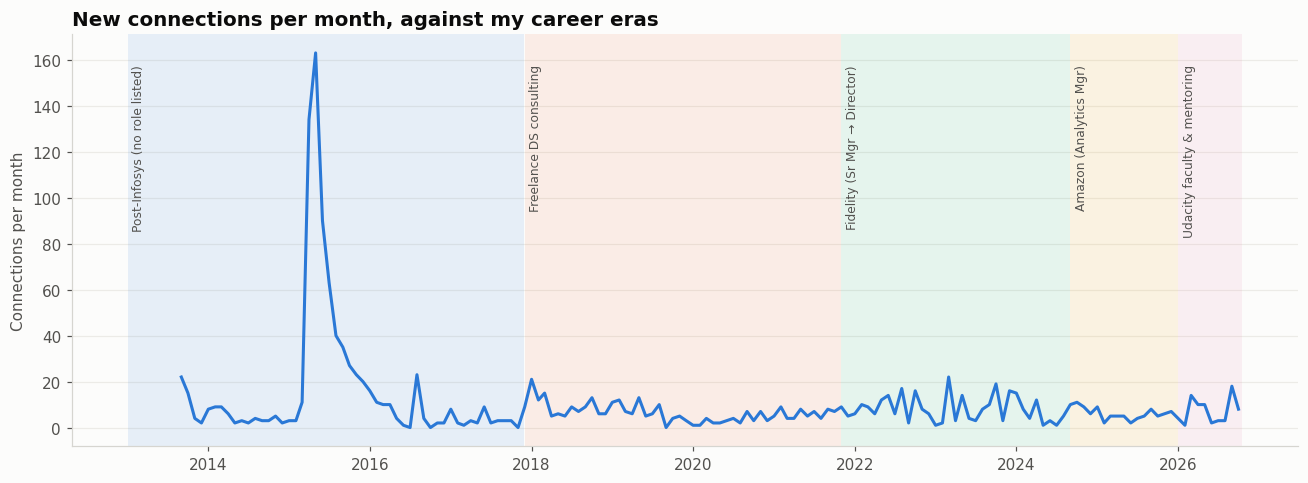

In [18]:
# Connections per month with my job eras shaded behind them
monthly = df.set_index("Connected On").resample("MS").size()
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, (label, start, end) in enumerate(ERAS):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=PALETTE[i], alpha=0.10, lw=0)
    ax.text(pd.Timestamp(start) + pd.Timedelta(days=20), monthly.max() * 0.97, label.split(" · ")[1],
            fontsize=8, color=INK_2, va="top", rotation=90)
ax.plot(monthly.index, monthly.values, color=PALETTE[0], lw=2)
ax.set_title("New connections per month, against my career eras", loc="left")
ax.set_ylabel("Connections per month")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

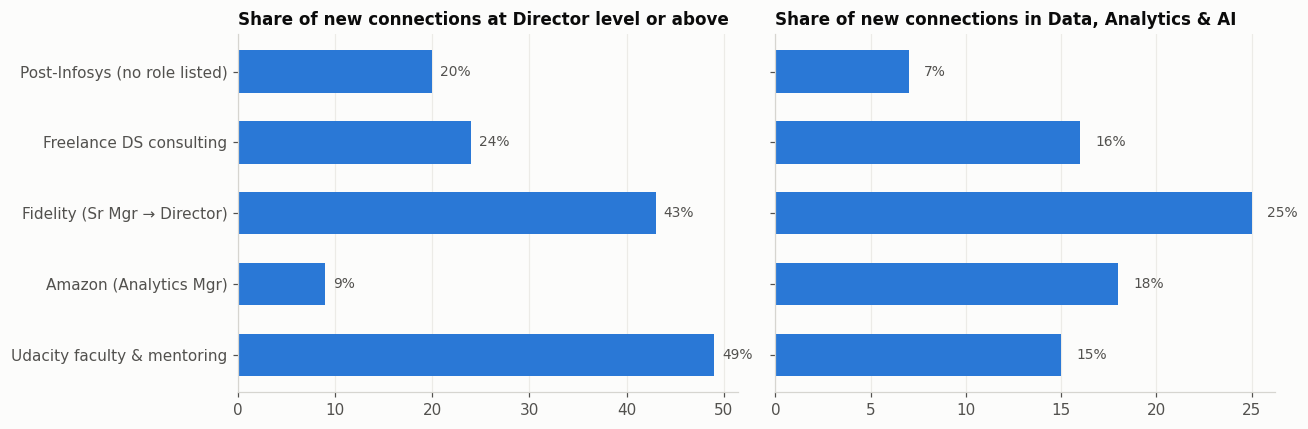

In [19]:
# Two measures that track my own career: seniority of who I connect with, and data/AI share
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
short = [e.split(" · ")[1] for e in eras_table.index]
for ax, col, title in [(axes[0], "Director+ %", "Share of new connections at Director level or above"),
                       (axes[1], "Data/AI %", "Share of new connections in Data, Analytics & AI")]:
    ax.barh(short[::-1], eras_table[col].values[::-1], color=PALETTE[0], height=0.6)
    for i, v in enumerate(eras_table[col].values[::-1]):
        ax.text(v + 0.8, i, f"{v}%", va="center", color=INK_2, fontsize=9)
    ax.set_title(title, loc="left", fontsize=11); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [20]:
# Zoom on the 2015 spike: when, and who
y15 = df[df["Year"] == 2015]
print("2015 connections by month:")
print(y15["Connected On"].dt.strftime("%b").value_counts().reindex(
    pd.date_range("2015-01-01", periods=12, freq="MS").strftime("%b")).fillna(0).astype(int).to_string())
print(f"\nBusiest single day: {y15['Connected On'].value_counts().max()} connections")
print("\nTop companies in 2015:", y15["Company (normalized)"].value_counts().head(6).to_dict())

2015 connections by month:
Jan      3
Feb      3
Mar     11
Apr    134
May    163
Jun     90
Jul     63
Aug     40
Sep     35
Oct     27
Nov     23
Dec     20

Busiest single day: 23 connections

Top companies in 2015: {'Infosys': 31, 'Accenture': 17, 'Unknown': 16, 'Amazon': 14, 'Deloitte': 11, 'Google': 9}


### Reading the timeline (Oct 2026 export)

**1. 2015 was a one-off push, not steady growth.** 612 connections (39% of the whole network) came in 2015,
about 300 of them in April and May alone, peaking at over 20 a day. Most were Infosys, Accenture, TCS and other
Indian IT-services people. This was **four years after leaving Infosys**, during a period with no role listed.
That pattern (a short burst, mostly former-employer and industry peers) looks like a deliberate reconnection
drive or a contacts import, not people met through day-to-day work.

**2. Since then the network has mostly grown through employers.** Each job brings in that company's people:
nearly all ~90 Fidelity connections were made while I worked there, and about half of the ~80 Amazon connections
were made during my time there. Between full-time roles (the freelance era) the pace drops and connections become
scattered: small companies, freelancers, recruiters.

**3. Seniority follows my role.** As a Senior Manager and then Director at Fidelity, **~43% of new connections were
Director level or above**, the highest of any era. At Amazon, in a manager role on a large team, that fell to
**~9%** (mostly peers). In 2026, as faculty, mentor and writer, it rose to ~49%, with **about a third founders or
C-suite**.

**4. The steady rate is 6–8 connections a month** (about 20 a quarter since 2021). That's work-driven growth.
2015 is the only stretch that looks like active network building.

**5. My move into data and AI shows up in the network.** Data/AI share grows from ~7% (pre-2017) to ~16%
(freelance data science) to ~25% (Fidelity analytics leadership), matching the move from analyst to analytics
leader.

**Caveats**
- *Company* and *Position* are each person's **current** values at export time, not their values when we
  connected. Someone who was a Fidelity colleague and later moved shows under their new company, so
  "from then-employer" counts are a **lower bound**.
- The 2011–2017 gap may just mean roles are missing from my profile, not that there was no job.
- Era boundaries come from month-level start/end dates, so connections near a job change may sit in the
  neighbouring era.

**So what:** to widen the network, the gaps are **industry** (healthcare, retail, the public sector) and
**deliberate outreach outside employers**. The 2026 shift toward founders and executives is the first change
in years that doesn't come from a new job.

## 10. Summary & export

In [21]:
def top(series, n=3):
    vc = series[~series.isin(["Unknown", "Other"])].value_counts(normalize=True).head(n) * 100
    return ", ".join(f"{k} ({v:.0f}%)" for k, v in vc.items())

senior = df["Seniority"].isin(["C-Suite / Founder", "VP / Head", "Director"]).mean() * 100
print(f"Total connections:            {len(df):,}")
print(f"Top companies:                {top(df['Company (normalized)'], 5)}")
print(f"Top company categories:       {top(df['Company Category'])}")
print(f"Top functions:                {top(df['Function'])}")
print(f"Top seniority levels:         {top(df['Seniority'].astype(str))}")
print(f"Director-level and above:     {senior:.0f}%")
print(f"Busiest connection year:      {int(year_counts.idxmax())} ({year_counts.max():,})")
print(f"Connected in last 3 years:    {(df['Year'] >= df['Year'].max() - 2).sum():,}")
print(f"Unclassified function:        {(df['Function'].isin(['Other','Unknown'])).mean()*100:.0f}%")

Total connections:            1,587
Top companies:                Fidelity Investments (6%), Amazon (5%), Infosys (3%), Accenture (2%), Google (1%)
Top company categories:       Other / Startups (49%), IT Services & Consulting (16%), Financial Services (13%)
Top functions:                Engineering & IT (21%), Management (general) (15%), Data, Analytics & AI/ML (14%)
Top seniority levels:         Individual Contributor (25%), Manager (23%), Lead / Principal / Staff (13%)
Director-level and above:     26%
Busiest connection year:      2015 (612)
Connected in last 3 years:    221
Unclassified function:        7%


In [22]:
cols = ["First Name", "Last Name", "URL", "Company", "Company (normalized)", "Company Category",
        "Position", "Function", "Seniority", "Career Era", "Connected On", "Year"]
df[cols].to_csv("connections_segmented.csv", index=False)
print("Saved connections_segmented.csv")

Saved connections_segmented.csv
